Au, J., Wong, C.Y.S., Pincot, D.D.A., Martin, F.N., Ray, R., Earles, M., Magney, T.S. (2025). *Leaf hyperspectral reflectance detects pre-visual stress to Fusarium wilt in strawberries.* Plant Phenome Journal 8(1):e70046. https://doi.org/10.1002/ppj2.70046 (CC BY 4.0)

**Code & data:** Zenodo record [16217833](https://doi.org/10.5281/zenodo.16217833) (version record, published 2025-07-20, CC BY 4.0): `Au_Fusarium_Strawberry_Figures_AnalysisCode.R`, `R_functions.R`, `Au_Fus_Strawberry_data.csv` (18.5 MB).

## What this notebook does / このノートブックの内容
This notebook executes the **authors' deposited R analysis code verbatim** on the authors' deposited dataset, inside Colab. It reproduces the paper's spectral-lead-time evidence: weekly leaf reflectance spectra (339–2515 nm) of 14 strawberry cultivars inoculated with *Fusarium oxysporum* f. sp. *fragariae*, the five spectral vegetation indices (NDVI, PRI, NPQI, NDWI, WBI), the Fisher exact test on disease scores, and t-tests / Wilcoxon tests on the indices (paper Table 1 and Figures 2–6).

このノートブックは、著者らが Zenodo に公開した **R 解析コードをそのまま** Colab 上で実行します。14 品種のイチゴ葉の週次高スペクトル反射率データ（339–2515 nm）、5 つのスペクトル指標（NDVI, PRI, NPQI, NDWI, WBI）、病害スコアの Fisher 正確検定、指標の t 検定 / Wilcoxon 検定（論文 Table 1・Figure 2–6）を再現します。

**Language note / 言語に関する注記:** The authors' implementation is **R** (R 4.2.1 with tidyverse/rstatix). Python is used **only as a launcher** (this notebook's kernel is Python; it installs R, downloads the pinned Zenodo files, and runs `Rscript` with checked subprocess calls). The author R file is not edited; a thin AI-written `runner.R` wrapper only un-comments the authors' own Figure-2 `ggsave` line and writes the lead-time table CSVs (the authors' own commented-out export lines).

## Runtime / ランタイム
**Select a CPU runtime / CPU ランタイムを選択してください.** No GPU is needed: this is a classical statistics + plotting workload (no torch, no model inference). Expected total time ≈ 15–25 min (R + package install ~5–10 min, 18.5 MB dataset download, analysis a few minutes). Use **Runtime → Run all**.

## Scope and limitations / 範囲と限界
- Reproduces Table 1 lead-time statistics and Figures 2–6 from the deposited code. It does **not** verify dataset-level accuracy claims beyond these outputs.
- Omitted (not present in the deposited script): the paper's Figure 7 full-spectrum analyses (PCoA on Bray–Curtis dissimilarity, per-wavelength CV and Spearman correlations, PERMANOVA). The deposited code ends at Figure 6, so those analyses cannot be run verbatim and are not invented here.
- The study design has no uninoculated control plants (a stated limitation of the paper).
- 論文 Figure 7 の全スペクトル解析（PCoA・CV・Spearman・PERMANOVA）はデポジットされたコードに含まれないため省略します。本研究デザインには非接種対照区がありません（論文自明の限界）。

### 1. Environment — install R / 環境: R のインストール
Installs the R runtime via apt if missing (a few minutes, streamed output). Python stays the notebook kernel and only orchestrates.
R が無ければ apt でインストールします（数分、出力は随時表示）。Python は実行の母艦のみ。

In [ ]:
# Install R (Colab Python images do not ship R by default). Python here is only the launcher.
# R をインストールします（Colab の Python イメージには R が入っていません）。
import subprocess

probe = subprocess.run(["bash", "-lc", "command -v Rscript || echo MISSING"],
                       capture_output=True, text=True)
if "Rscript" not in probe.stdout:
    print("Installing R via apt ...")
    subprocess.run(["bash", "-lc", "apt-get update -qq && apt-get install -y -qq r-base"], check=True)
else:
    print("Rscript already present.")

ver = subprocess.run(["Rscript", "-e", "cat(R.version.string)"],
                     capture_output=True, text=True, check=True)
print("R runtime:", ver.stdout)

Rscript already present.


R runtime: R version 4.6.1 (2026-06-24)


### 2. Environment — R packages / 環境: R パッケージ
Installs `tidyverse`, `rstatix`, `cowplot`, `ggnewscale` (all imported by the author code) as prebuilt binaries for this Ubuntu release; falls back to CRAN source if a binary is unavailable, then prints installed versions.
著者コードが利用する 4 パッケージをバイナリでインストールし、バージョンを表示します。

In [ ]:
# Install the author-required R packages as fast prebuilt binaries from the
# Posit Package Manager (P3M) mirror for this Ubuntu release, with a CRAN-source fallback.
# 著者コードが必要とする R パッケージを P3M のバイナリで高速インストールします（失敗時はソースから）。
import subprocess

codename = subprocess.run(["bash", "-lc", ". /etc/os-release && echo $VERSION_CODENAME"],
                          capture_output=True, text=True).stdout.strip()
print("Ubuntu codename:", codename)
p3m = f"https://packagemanager.posit.co/cran/__linux__/{codename}/latest"

install_r = f"""options(repos = c(P3M = "{p3m}"), timeout = 600, Ncpus = 4)
pkgs <- c("tidyverse", "rstatix", "cowplot", "ggnewscale")
install.packages(pkgs)
ok <- sapply(pkgs, function(p) requireNamespace(p, quietly = TRUE))
print(ok)
if (!all(ok)) {{
  message("Falling back to CRAN source for missing packages")
  options(repos = c(CRAN = "https://cloud.r-project.org"))
  install.packages(names(ok)[!ok])
  print(sapply(pkgs, function(p) requireNamespace(p, quietly = TRUE)))
}}"""
with open("/content/install_pkgs.R", "w") as f:
    f.write(install_r)
subprocess.run(["Rscript", "/content/install_pkgs.R"], check=True)

chk = subprocess.run(
    ["Rscript", "-e",
     'for (p in c("tidyverse","rstatix","cowplot","ggnewscale")) '
     'cat(p, as.character(packageVersion(p)), "\\n")'],
    capture_output=True, text=True, check=True)
print(chk.stdout)

Ubuntu codename: noble


tidyverse 2.0.0 
rstatix 1.1.0 
cowplot 1.2.0 
ggnewscale 0.5.2 



### 3. Inputs — pinned Zenodo download and verification / 入力のダウンロードと検証
Downloads the three files of Zenodo record **16217833** (the paper-linked version record) and asserts exact byte size and MD5 for each before use. The dataset CSV stays on the Colab VM.
Zenodo レコード 16217833 の 3 ファイルを取得し、サイズと MD5 を検証します。CSV は Colab VM 上に置かれます。

In [ ]:
# Download the pinned Zenodo record files (record 16217833) and verify size + MD5
# against the record metadata retrieved and checked on the host before authoring.
# Zenodo レコード 16217833 からファイルを取得し、サイズと MD5 を検証します。
import hashlib, json, urllib.request

RECORD = 16217833
EXPECTED = {
    "Au_Fusarium_Strawberry_Figures_AnalysisCode.R": (19267, "769688bac2ebe076fa9ac16d460a59a1"),
    "R_functions.R": (5962, "011ba1b3ac5698fa9ab7a62ad4c94875"),
    "Au_Fus_Strawberry_data.csv": (18471329, "a2ab930a8f284a8792195f94c9c8a537"),
}
with urllib.request.urlopen(f"https://zenodo.org/api/records/{RECORD}", timeout=120) as r:
    meta = json.load(r)
print("Record title:", meta["metadata"]["title"])
print("Record DOI:", meta["doi"])

for f in meta["files"]:
    key = f["key"]
    assert key in EXPECTED, f"unexpected file {key} in record"
    size, md5 = EXPECTED[key]
    dest = f"/content/{key}"
    print(f"Downloading {key} ({size} bytes) ...", flush=True)
    with urllib.request.urlopen(f["links"]["self"], timeout=600) as resp, open(dest, "wb") as out:
        h = hashlib.md5()
        n = 0
        while True:
            chunk = resp.read(1 << 20)
            if not chunk:
                break
            out.write(chunk)
            h.update(chunk)
            n += len(chunk)
    assert n == size, f"{key}: expected {size} bytes, got {n}"
    assert h.hexdigest() == md5, f"{key}: MD5 mismatch ({h.hexdigest()})"
    print(f"  OK: {n} bytes, md5 {h.hexdigest()}")

# Arrange the layout the author script expects: script + R_functions.R in the
# working directory, CSV under Data/ (author path: "Data/Au_Fus_Strawberry_data.csv").
import os, shutil
os.makedirs("/content/work/Data", exist_ok=True)
shutil.copy("/content/Au_Fusarium_Strawberry_Figures_AnalysisCode.R", "/content/work/")
shutil.copy("/content/R_functions.R", "/content/work/")
shutil.copy("/content/Au_Fus_Strawberry_data.csv", "/content/work/Data/")
print("Files arranged under /content/work")

Record title: Leaf hyperspectral reflectance detects pre-visual stress to Fusarium wilt in strawberries: Dataset and Code
Record DOI: 10.5281/zenodo.16217833


  OK: 19267 bytes, md5 769688bac2ebe076fa9ac16d460a59a1


  OK: 5962 bytes, md5 011ba1b3ac5698fa9ab7a62ad4c94875


  OK: 18471329 bytes, md5 a2ab930a8f284a8792195f94c9c8a537
Files arranged under /content/work


### 4. Input preview — dataset schema / 入力プレビュー: データ概要
Shows the actual downloaded dataset's shape, wavelength coverage, measurement dates, cultivar/replicate counts, and score ranges — the verified input for everything below.
ダウンロードしたデータの実体（行数・波長・日付・品種・スコア範囲）を表示します。

In [ ]:
# Input schema preview: dimensions, columns, measurement dates, cultivar entries,
# and disease-score ranges of the authors' deposited dataset (verified bytes above).
# 入力データの概要（行数・列・測定日・品種・スコア範囲）を確認します。
import pandas as pd

df = pd.read_csv("/content/work/Data/Au_Fus_Strawberry_data.csv")
print("shape (rows, cols):", df.shape)
wl_cols = [c for c in df.columns if c.isdigit()]
print(f"wavelength columns: {len(wl_cols)} ({wl_cols[0]}–{wl_cols[-1]} nm)")
print("non-spectral columns:", [c for c in df.columns if c not in wl_cols])
dates = sorted(str(d) for d in df["Date"].unique())
print(f"measurement dates ({len(dates)}):", dates)
print("cultivar entries:", df["Entry"].nunique(), "| replicates:", df["Rep"].nunique())
print("Score range:", df["Score"].min(), "-", df["Score"].max(),
      "| FinalScore range:", df["FinalScore"].min(), "-", df["FinalScore"].max())
print("FinalScoreBin values:", sorted(df["FinalScoreBin"].dropna().unique()),
      "(0 = resistant, 1 = susceptible; per author code)")
df[[c for c in ["Date", "Entry", "Rep", "Score", "FinalScore", "FinalScoreBin",
                "NDVI", "PRI", "NPQI", "NDWI", "WBI"] if c in df.columns]].head(8)

shape (rows, cols): (935, 2199)
wavelength columns: 2177 (339–2515 nm)
non-spectral columns: ['Entry', 'FinalScore', 'FinalScoreBin', 'Rep', 'Date', 'Score', 'Pathogen', 'ScoreBin', 'gsw', 'VPDleaf', 'PhiPS2', 'Tref', 'Tleaf', 'Qamb', 'Fv/Fm', 'NPQ', 'PhiPS2calc', 'NDVI', 'PRI', 'NDWI', 'WBI', 'NPQI']
measurement dates (17): ['2021-04-02', '2021-04-09', '2021-04-16', '2021-04-23', '2021-04-30', '2021-05-07', '2021-05-14', '2021-05-21', '2021-05-28', '2021-06-04', '2021-06-11', '2021-06-18', '2021-06-25', '2021-07-02', '2021-07-09', '2021-07-15', '2021-07-23']
cultivar entries: 14 | replicates: 4
Score range: 1.0 - 5.0 | FinalScore range: 1.0 - 5.0
FinalScoreBin values: [np.int64(0), np.int64(1)] (0 = resistant, 1 = susceptible; per author code)


,Date,Entry,Rep,Score,FinalScore,FinalScoreBin,NDVI,PRI,NPQI,NDWI,WBI
0,2021-04-02,01C132P003,A,1.0,4.5,1,NaN,NaN,NaN,NaN,NaN
1,2021-04-02,01C132P003,B,1.0,4.5,1,NaN,NaN,NaN,NaN,NaN
2,2021-04-02,01C132P003,C,1.0,4.5,1,NaN,NaN,NaN,NaN,NaN
3,2021-04-02,01C132P003,D,1.0,4.5,1,NaN,NaN,NaN,NaN,NaN
4,2021-04-09,01C132P003,A,1.0,4.5,1,NaN,NaN,NaN,NaN,NaN
5,2021-04-09,01C132P003,B,1.0,4.5,1,NaN,NaN,NaN,NaN,NaN
6,2021-04-09,01C132P003,C,1.0,4.5,1,NaN,NaN,NaN,NaN,NaN
7,2021-04-09,01C132P003,D,1.0,4.5,1,NaN,NaN,NaN,NaN,NaN


### 5. Input preview — spectra plot / 入力プレビュー: スペクトル図
Plots cultivar-mean reflectance per date plus the authors' healthy reference mean and SVI bands. **This plot is an additional visualization created for this notebook**, in the spirit of the authors' Figure 2 (which is reproduced below from their own code).
日付別平均スペクトルと健全平均、SVI 帯を描きます（本ノートブック用の追加図。著者版 Figure 2 は後続）。

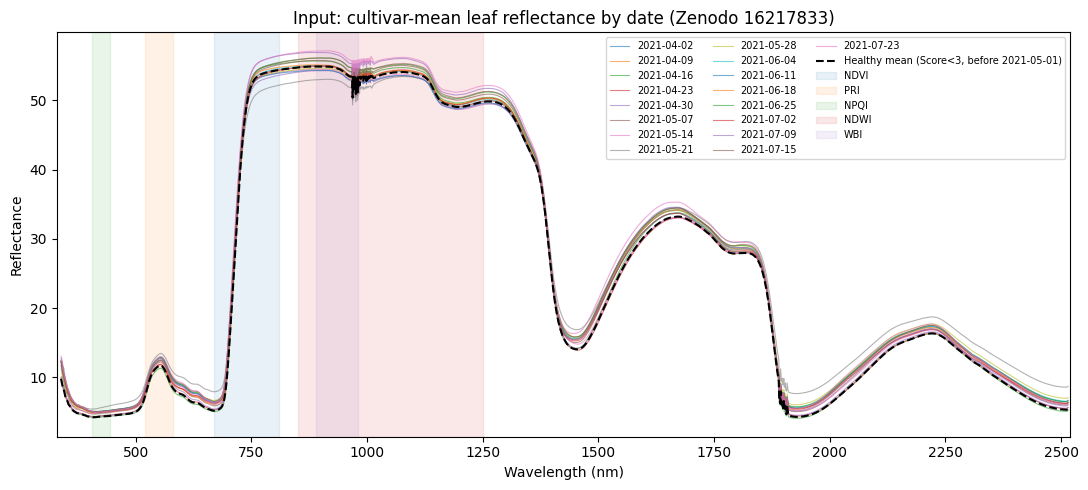

In [ ]:
# Input preview (additional AI-created plot, not an author figure): mean reflectance
# spectra per measurement date, plus the authors' "healthy" reference mean
# (Score < 3 and Date < 2021-05-01, per author code lines 27–35) and the SVI band pairs.
# 入力プレビュー（本ノートブック用に追加作成した図）: 日付別の平均反射率スペクトルと
# 著者定義の「健全」平均スペクトル、および 5 指標の波長帯。
import numpy as np
import matplotlib.pyplot as plt

wl = np.array([int(c) for c in wl_cols])
healthy = df[(df["Score"] < 3) & (df["Date"] < "2021-05-01")][wl_cols].mean(axis=0).values

fig, ax = plt.subplots(figsize=(11, 5))
for d, g in df.groupby("Date"):
    ax.plot(wl, g[wl_cols].mean(axis=0).values, lw=0.8, alpha=0.6, label=str(d))
ax.plot(wl, healthy, "k--", lw=1.5, label="Healthy mean (Score<3, before 2021-05-01)")
bands = {"NDVI": (680, 800), "PRI": (531, 570), "NPQI": (415, 435),
         "NDWI": (860, 1240), "WBI": (900, 970)}
for i, (name, (a, b)) in enumerate(bands.items()):
    ax.axvspan(min(a, b) - 10, max(a, b) + 10, alpha=0.10, color=f"C{i}", label=name)
ax.set(xlabel="Wavelength (nm)", ylabel="Reflectance", xlim=(330, 2520),
       title="Input: cultivar-mean leaf reflectance by date (Zenodo 16217833)")
ax.legend(ncol=3, fontsize=7, loc="upper right")
fig.tight_layout()
fig.savefig("/content/input_preview.png", dpi=120)
plt.show()

### 6. Core method — run the authors' R analysis / 本編: 著者 R コードの実行
Runs `Au_Fusarium_Strawberry_Figures_AnalysisCode.R` **verbatim** with `Rscript`. It computes the five SVIs from the reflectance columns, the per-date Fisher exact tests on disease scores, Shapiro–Wilk normality screening, t-tests / Wilcoxon on the entry-level weekly index means, and saves Figures 2–6 PNGs. The only wrapper additions are the authors' own commented-out Figure-2 save and lead-table CSV export.
著者の R スクリプトを**無修正**で Rscript 実行します（SVI 計算、Fisher 検定、Shapiro–Wilk、t / Wilcoxon 検定、Figure 2–6 の保存）。ラッパーは著者自身のコメント行の ggsave と CSV 出力のみ。

In [ ]:
# Execute the authors' deposited R analysis verbatim via Rscript (AI-written thin wrapper).
# The wrapper only (1) re-runs the authors' own commented-out Figure-2 ggsave line and
# (2) writes the lead-time table CSVs that the authors left commented in the deposit.
# Nothing else in the author file is modified.
# 著者の R 解析コードを Rscript でそのまま実行します。ラッパーは Figure 2 の ggsave
# （デポジット内でコメント化されている著者自身の行）とリードタイム表の CSV 出力のみ追加します。
runner_r = """setwd("/content/work")
source("Au_Fusarium_Strawberry_Figures_AnalysisCode.R")

# Author deposit line 75 (commented there): save Figure 2
ggsave("Figure2_SpectraPlot.png", plot = spectraPlot, width = 40, height = 20, units = "cm")

# Author deposit lines 336-342 (write.csv commented there): lead-time table
LeadTableDF_p = TestResults %>%
  bind_rows(pval) %>%
  select(-y.position, -p.signif) %>%
  pivot_wider(names_from = Date, values_from = p)
write.csv(LeadTableDF_p, "LeadTableDF_p.csv", row.names = FALSE)
write.csv(TestResults %>% bind_rows(pval) %>% select(Date, Index, p, p.signif),
          "lead_time_results_long.csv", row.names = FALSE)

cat(R.version.string, "\n")
cat("R_ANALYSIS_DONE\\n")
"""
with open("/content/work/runner.R", "w") as f:
    f.write(runner_r)

# R's C-level stdout bypasses Jupyter capture, so it is captured and re-printed
# to keep the completion marker inside the saved notebook output.
res = subprocess.run(["Rscript", "runner.R"], cwd="/content/work", check=True,
                     timeout=1800, capture_output=True, text=True)
print(res.stdout)
if res.stderr.strip():
    print("--- R stderr (messages/warnings, truncated) ---")
    print(res.stderr[-2000:])
import os
expected_pngs = ["Figure2_SpectraPlot.png", "Figure3_SpectralDiff.png",
                 "Figure4_ScoreIndexPlotb.png", "Figure5_IndexDiff.png",
                 "Figure6_PhysPlot.png"]
for p in expected_pngs:
    assert os.path.exists(f"/content/work/{p}"), f"missing output {p}"
    print(p, os.path.getsize(f"/content/work/{p}"), "bytes")

R version 4.6.1 (2026-06-24) 
R_ANALYSIS_DONE

--- R stderr (messages/warnings, truncated) ---
put.
ℹ Summaries were computed grouped by ScoreBin and FinalScoreBin.
ℹ Output is grouped by ScoreBin.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(ScoreBin, FinalScoreBin))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by ScoreBin and FinalScoreBin.
ℹ Output is grouped by ScoreBin.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(ScoreBin, FinalScoreBin))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.
New names:
• `` -> `...1`
Joining with `by = join_by(Date)`
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, Entry, and Index.
ℹ Output is grouped by Date and Entry.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, Entry, Index)

### 7. Results — lead-time table vs paper Table 1 / 結果: リードタイム表と論文 Table 1 の比較
Reads the test results produced by the authors' code and reports the first date each metric significantly diverges, side-by-side with the paper's Table 1 dates.
著者コードの出力から各指標の初回有意日を求め、論文 Table 1 と並べて表示します。

In [ ]:
# Lead-time results: first date each metric shows a significant resistant-vs-susceptible
# difference (p < 0.05), computed from the authors' own test outputs, compared with the
# paper's Table 1 dates (NPQI May 14, PRI May 28, NDVI/NDWI June 4, Score June 25).
# リードタイム結果: 各指標で最初に有意差（p < 0.05）が現れた日付を論文 Table 1 と比較します。
res = pd.read_csv("/content/work/lead_time_results_long.csv")
first_sig = (res[(res["p"] < 0.05)]
             .groupby("Index")["Date"].min())
paper_t1 = {"NPQI": "2021-05-14", "PRI": "2021-05-28",
            "NDVI": "2021-06-04", "NDWI": "2021-06-04", "Score": "2021-06-25"}
rows = []
for idx, paper_date in paper_t1.items():
    got = first_sig.get(idx, "none (never significant)")
    rows.append({"Index": idx,
                 "First significant date (computed)": got,
                 "Paper Table 1": paper_date,
                 "Match": str(got) == paper_date})
cmp_df = pd.DataFrame(rows)
print(cmp_df.to_string(index=False))
display(cmp_df)
cmp_df.to_csv("/content/work/lead_time_comparison.csv", index=False)

Index First significant date (computed) Paper Table 1  Match
 NPQI                        2021-05-14    2021-05-14   True
  PRI                        2021-05-28    2021-05-28   True
 NDVI                        2021-06-04    2021-06-04   True
 NDWI                        2021-06-04    2021-06-04   True
Score                        2021-06-25    2021-06-25   True


,Index,First significant date (computed),Paper Table 1,Match
0,NPQI,2021-05-14,2021-05-14,True
1,PRI,2021-05-28,2021-05-28,True
2,NDVI,2021-06-04,2021-06-04,True
3,NDWI,2021-06-04,2021-06-04,True
4,Score,2021-06-25,2021-06-25,True


### Output — Figure2_SpectraPlot.png / 出力表示
Authors' Figure 2: cultivar-mean reflectance spectra per date with the healthy reference mean and the five SVI band pairs highlighted (saved by the authors' own ggplot code). / 著者の Figure 2: 日付別平均スペクトル、健全平均、SVI 波長帯。

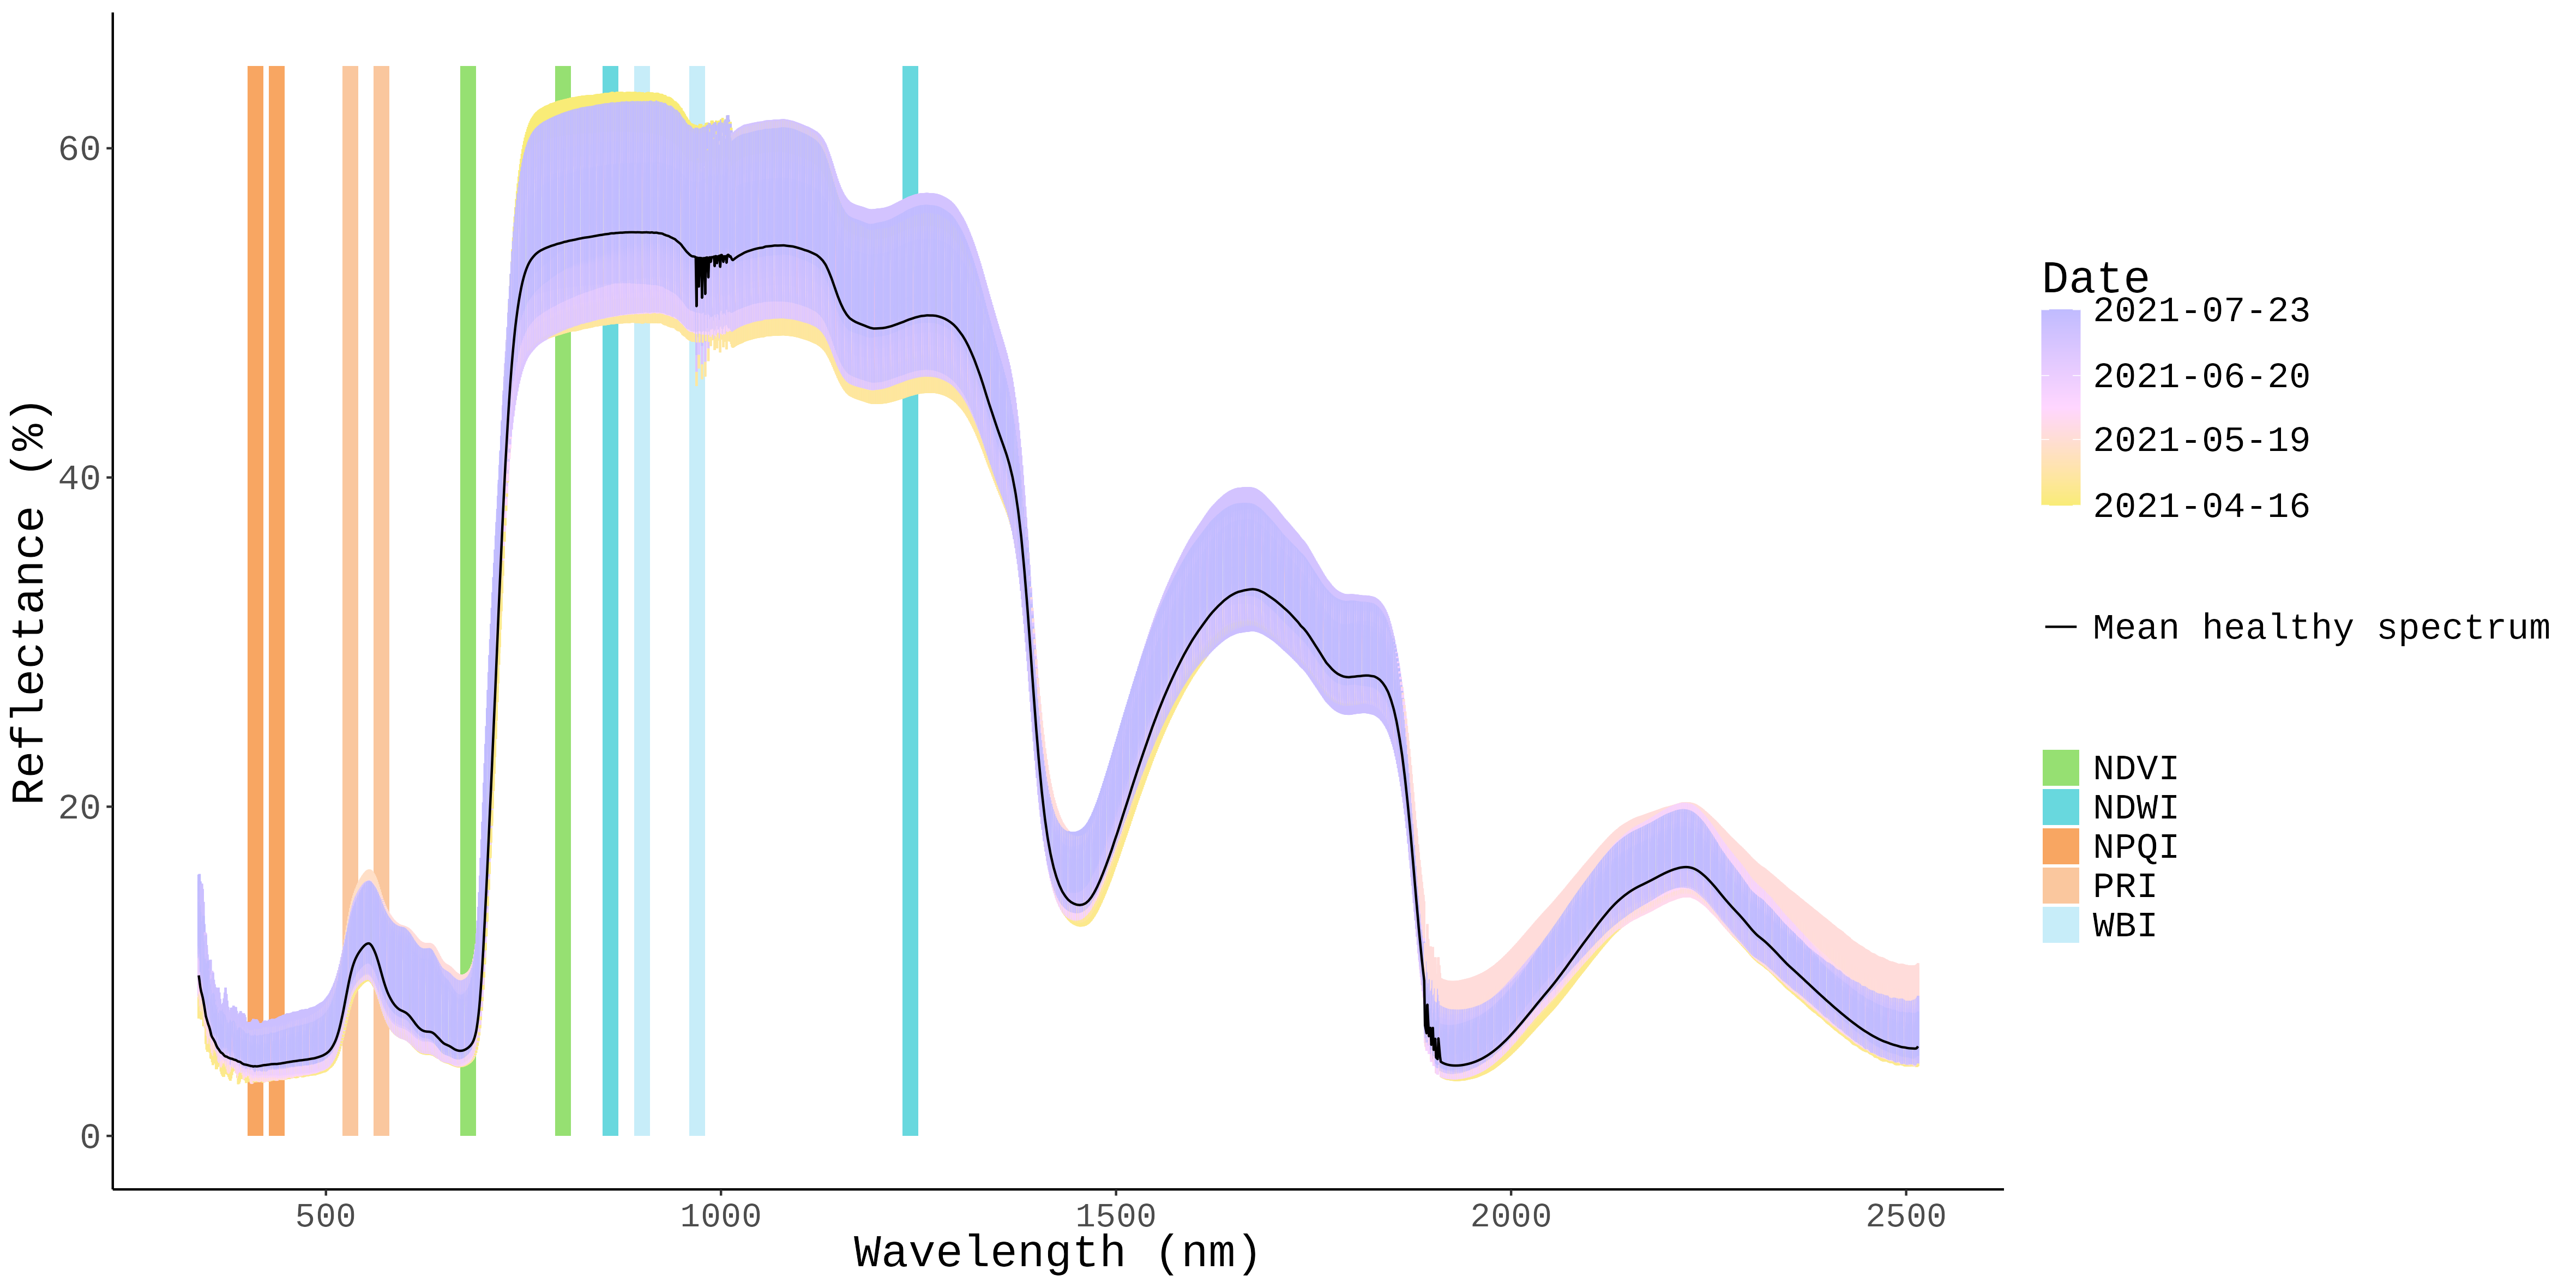

In [ ]:
# Display the authors' saved figure (written by their ggsave calls during the run above).
# 上で著者コードが保存した図を表示します。
from IPython.display import Image, display
display(Image(filename="/content/work/Figure2_SpectraPlot.png", width=900))

### Output — Figure3_SpectralDiff.png / 出力表示
Authors' Figure 3: reflectance difference from the healthy mean ± SE for resistant vs susceptible plants by date. / 著者の Figure 3: 健全平均からの反射率差（±SE）。

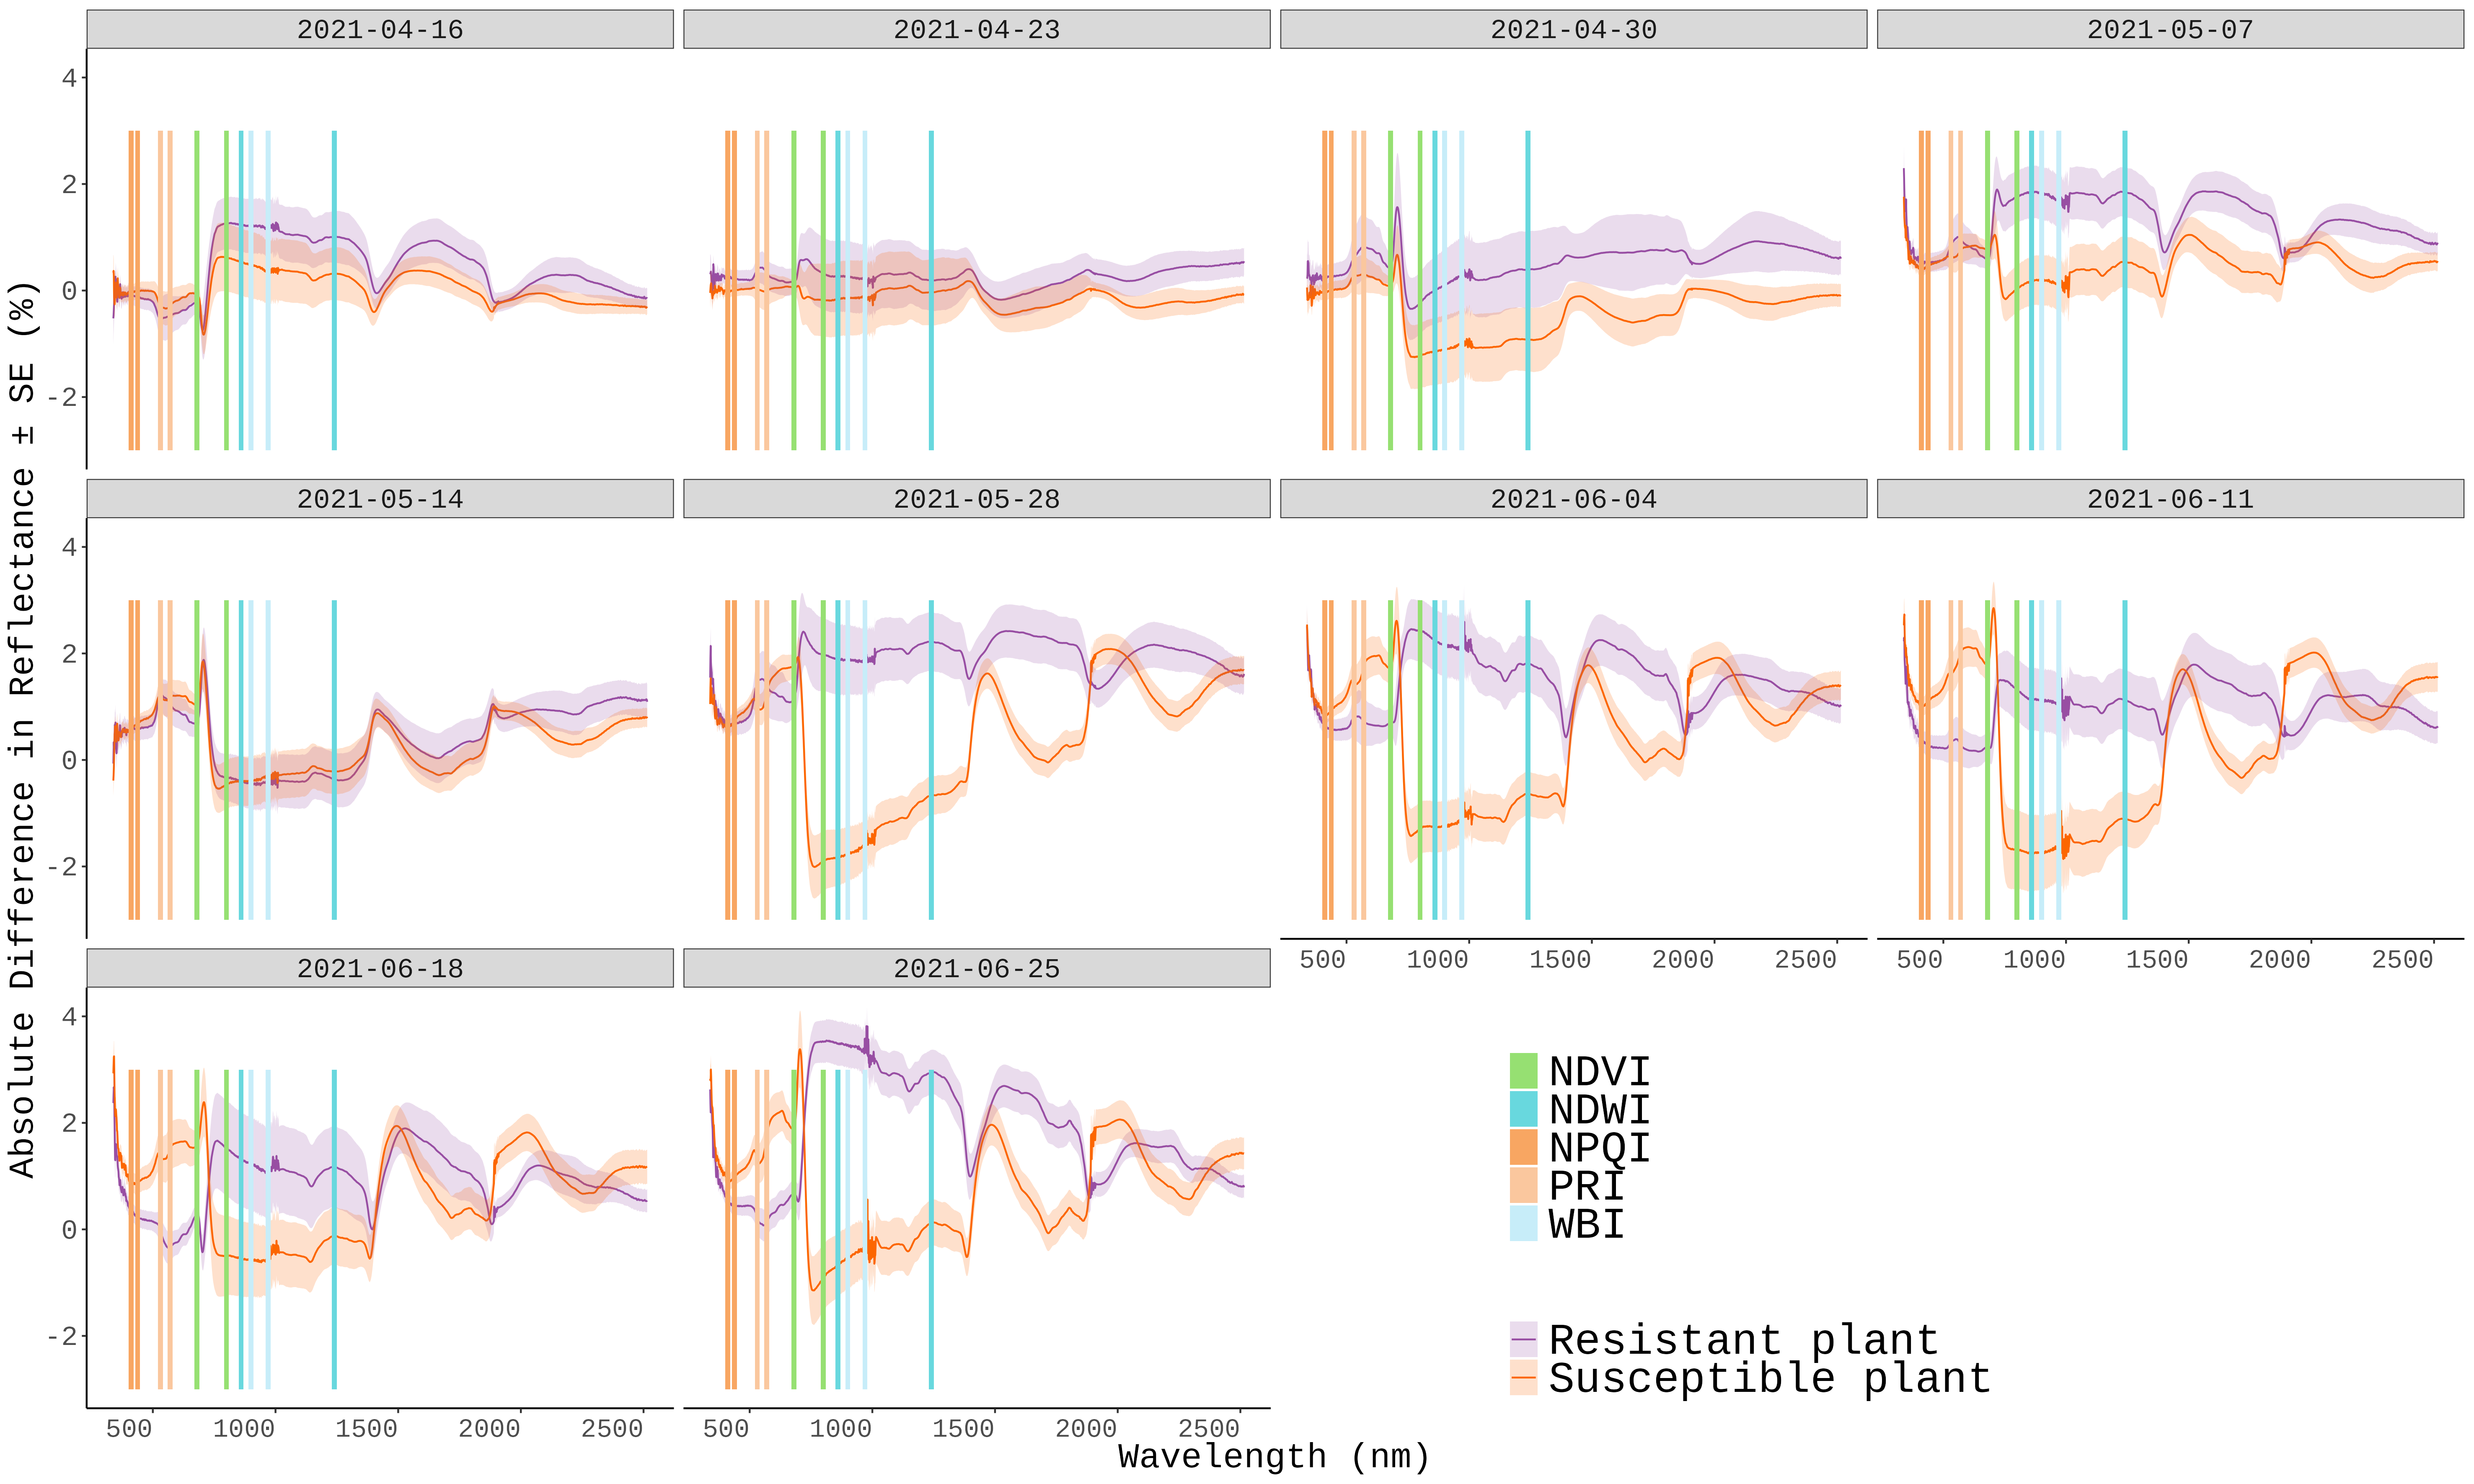

In [ ]:
# Display the authors' saved figure (written by their ggsave calls during the run above).
# 上で著者コードが保存した図を表示します。
from IPython.display import Image, display
display(Image(filename="/content/work/Figure3_SpectralDiff.png", width=900))

### Output — Figure4_ScoreIndexPlotb.png / 出力表示
Authors' Figure 4: disease-score counts with Fisher-test significance (a) and the five SVI time series with t/Wilcoxon significance (b–f). / 著者の Figure 4: スコアと 5 指標の時系列と有意差。

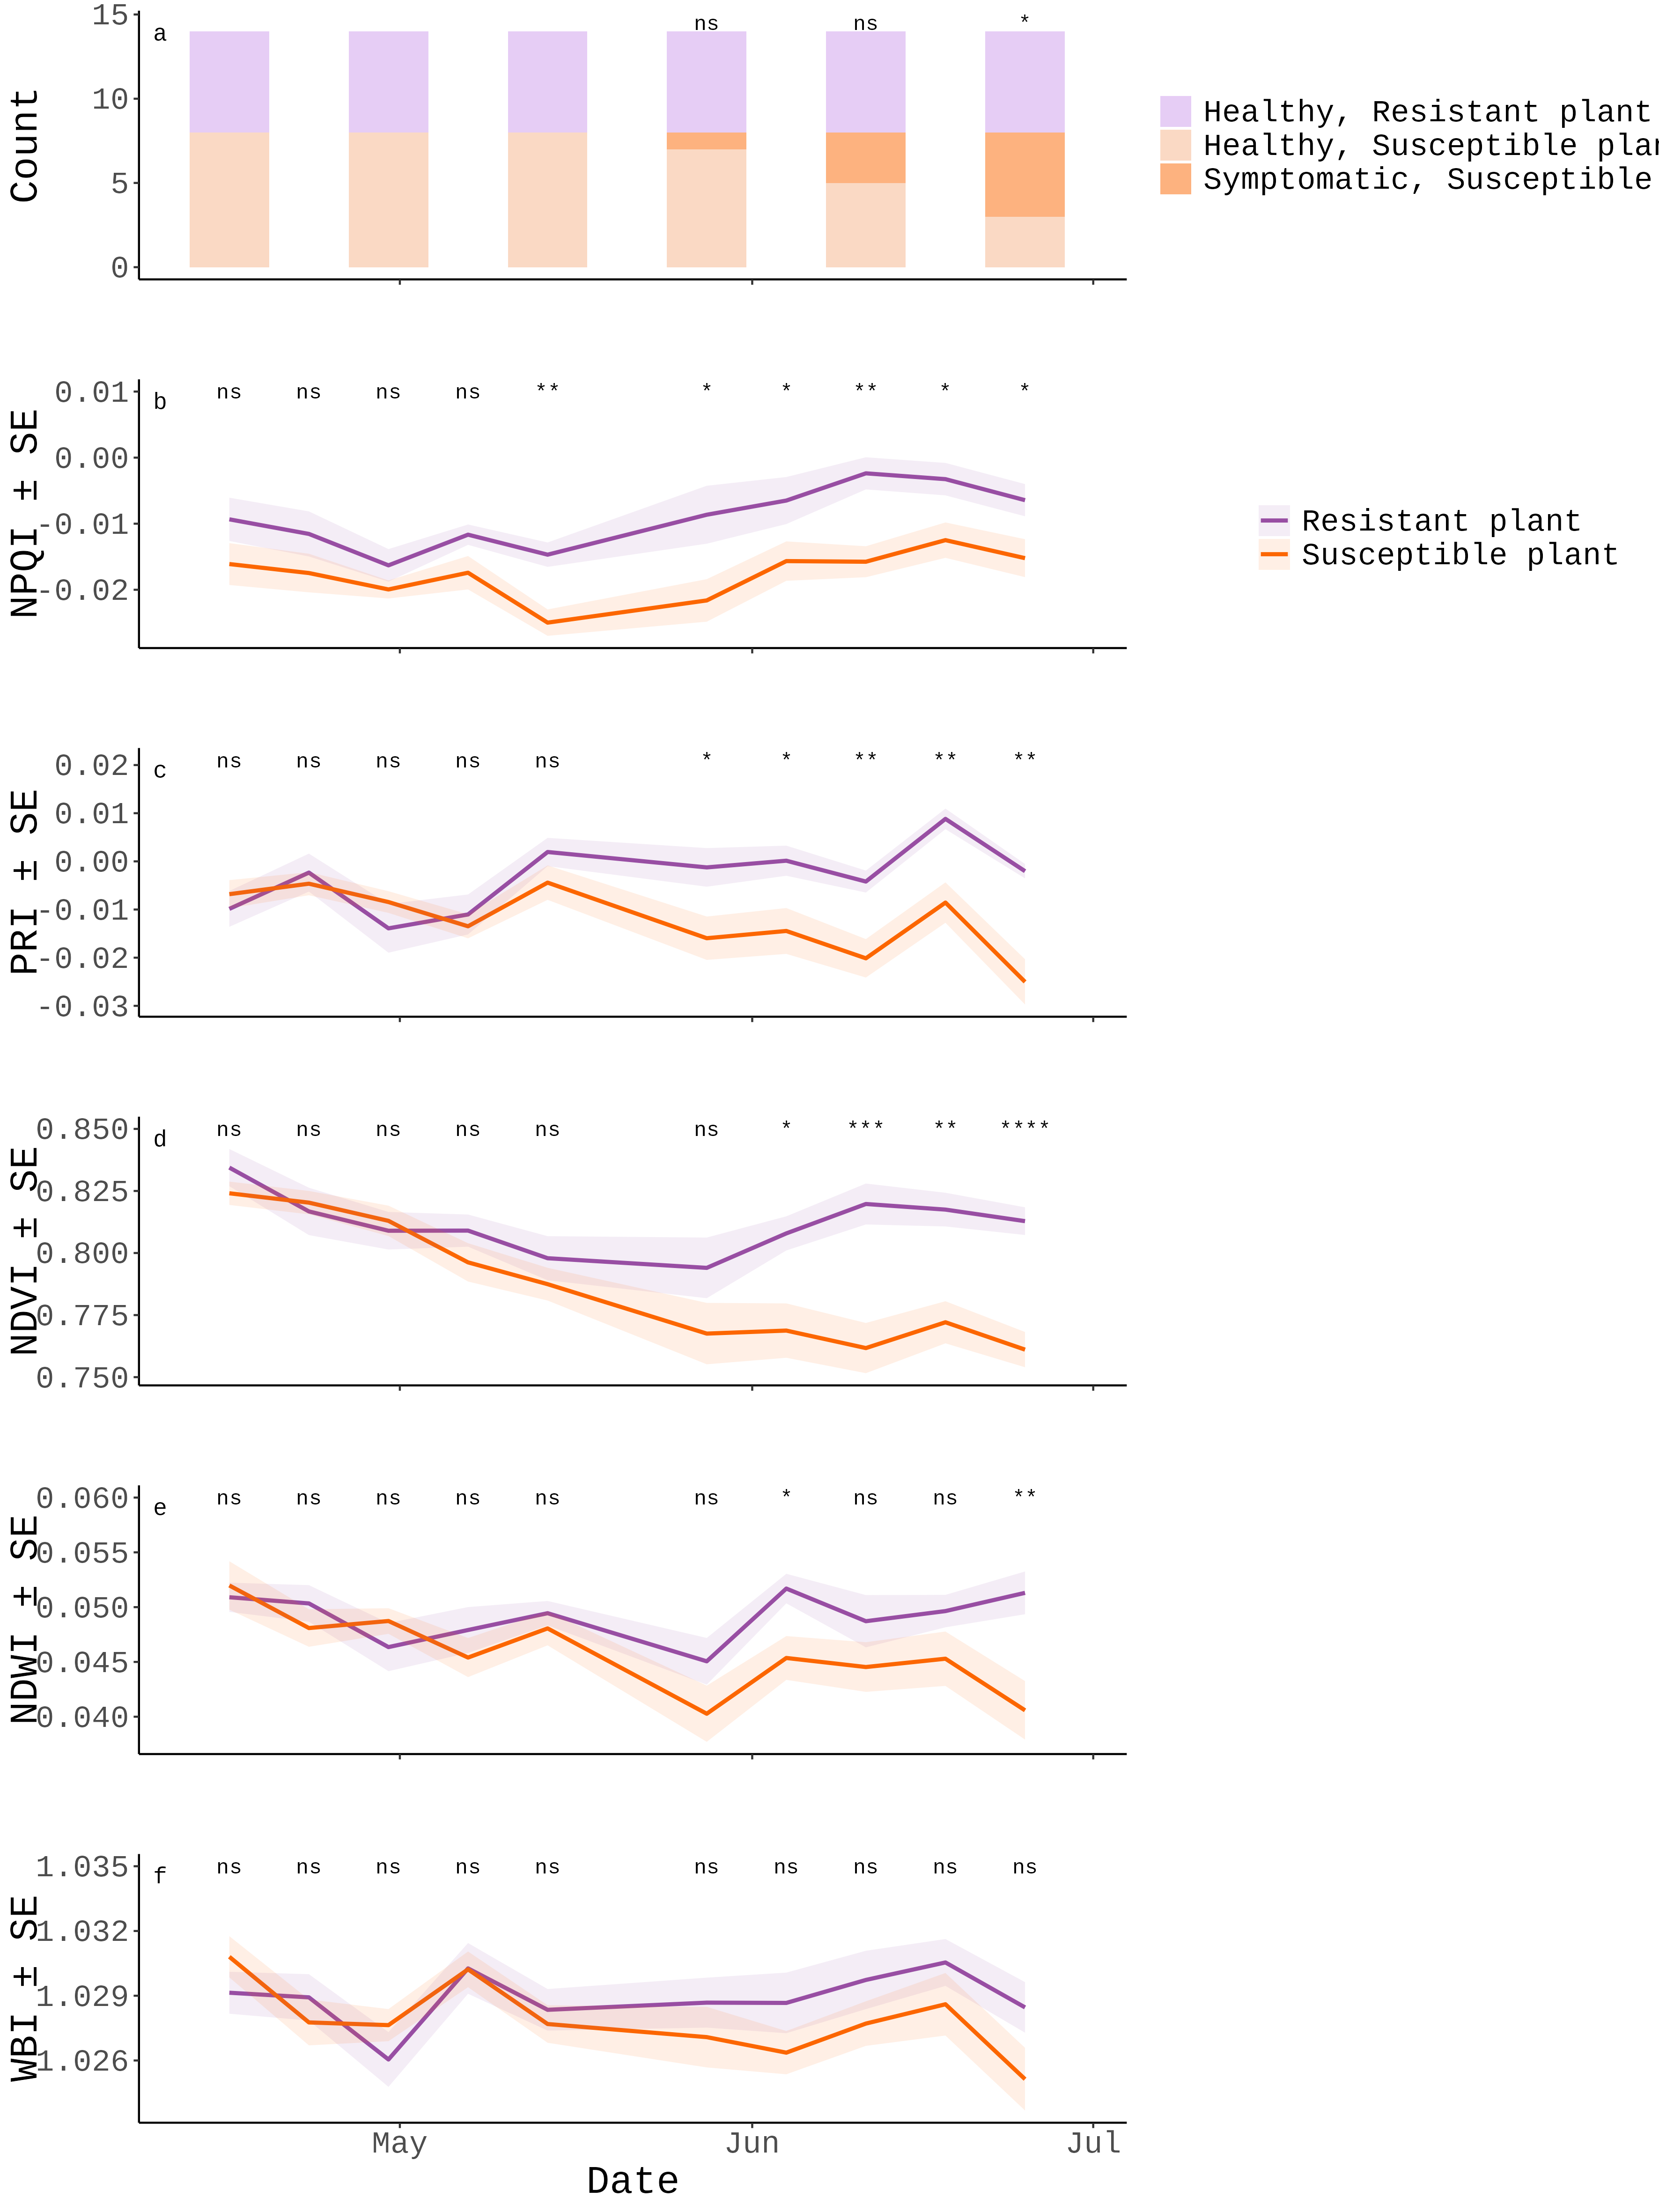

In [ ]:
# Display the authors' saved figure (written by their ggsave calls during the run above).
# 上で著者コードが保存した図を表示します。
from IPython.display import Image, display
display(Image(filename="/content/work/Figure4_ScoreIndexPlotb.png", width=900))

### Output — Figure5_IndexDiff.png / 出力表示
Authors' Figure 5: absolute index difference of susceptible plants from the resistant group ± SE. / 著者の Figure 5: 耐性群からの指数差。

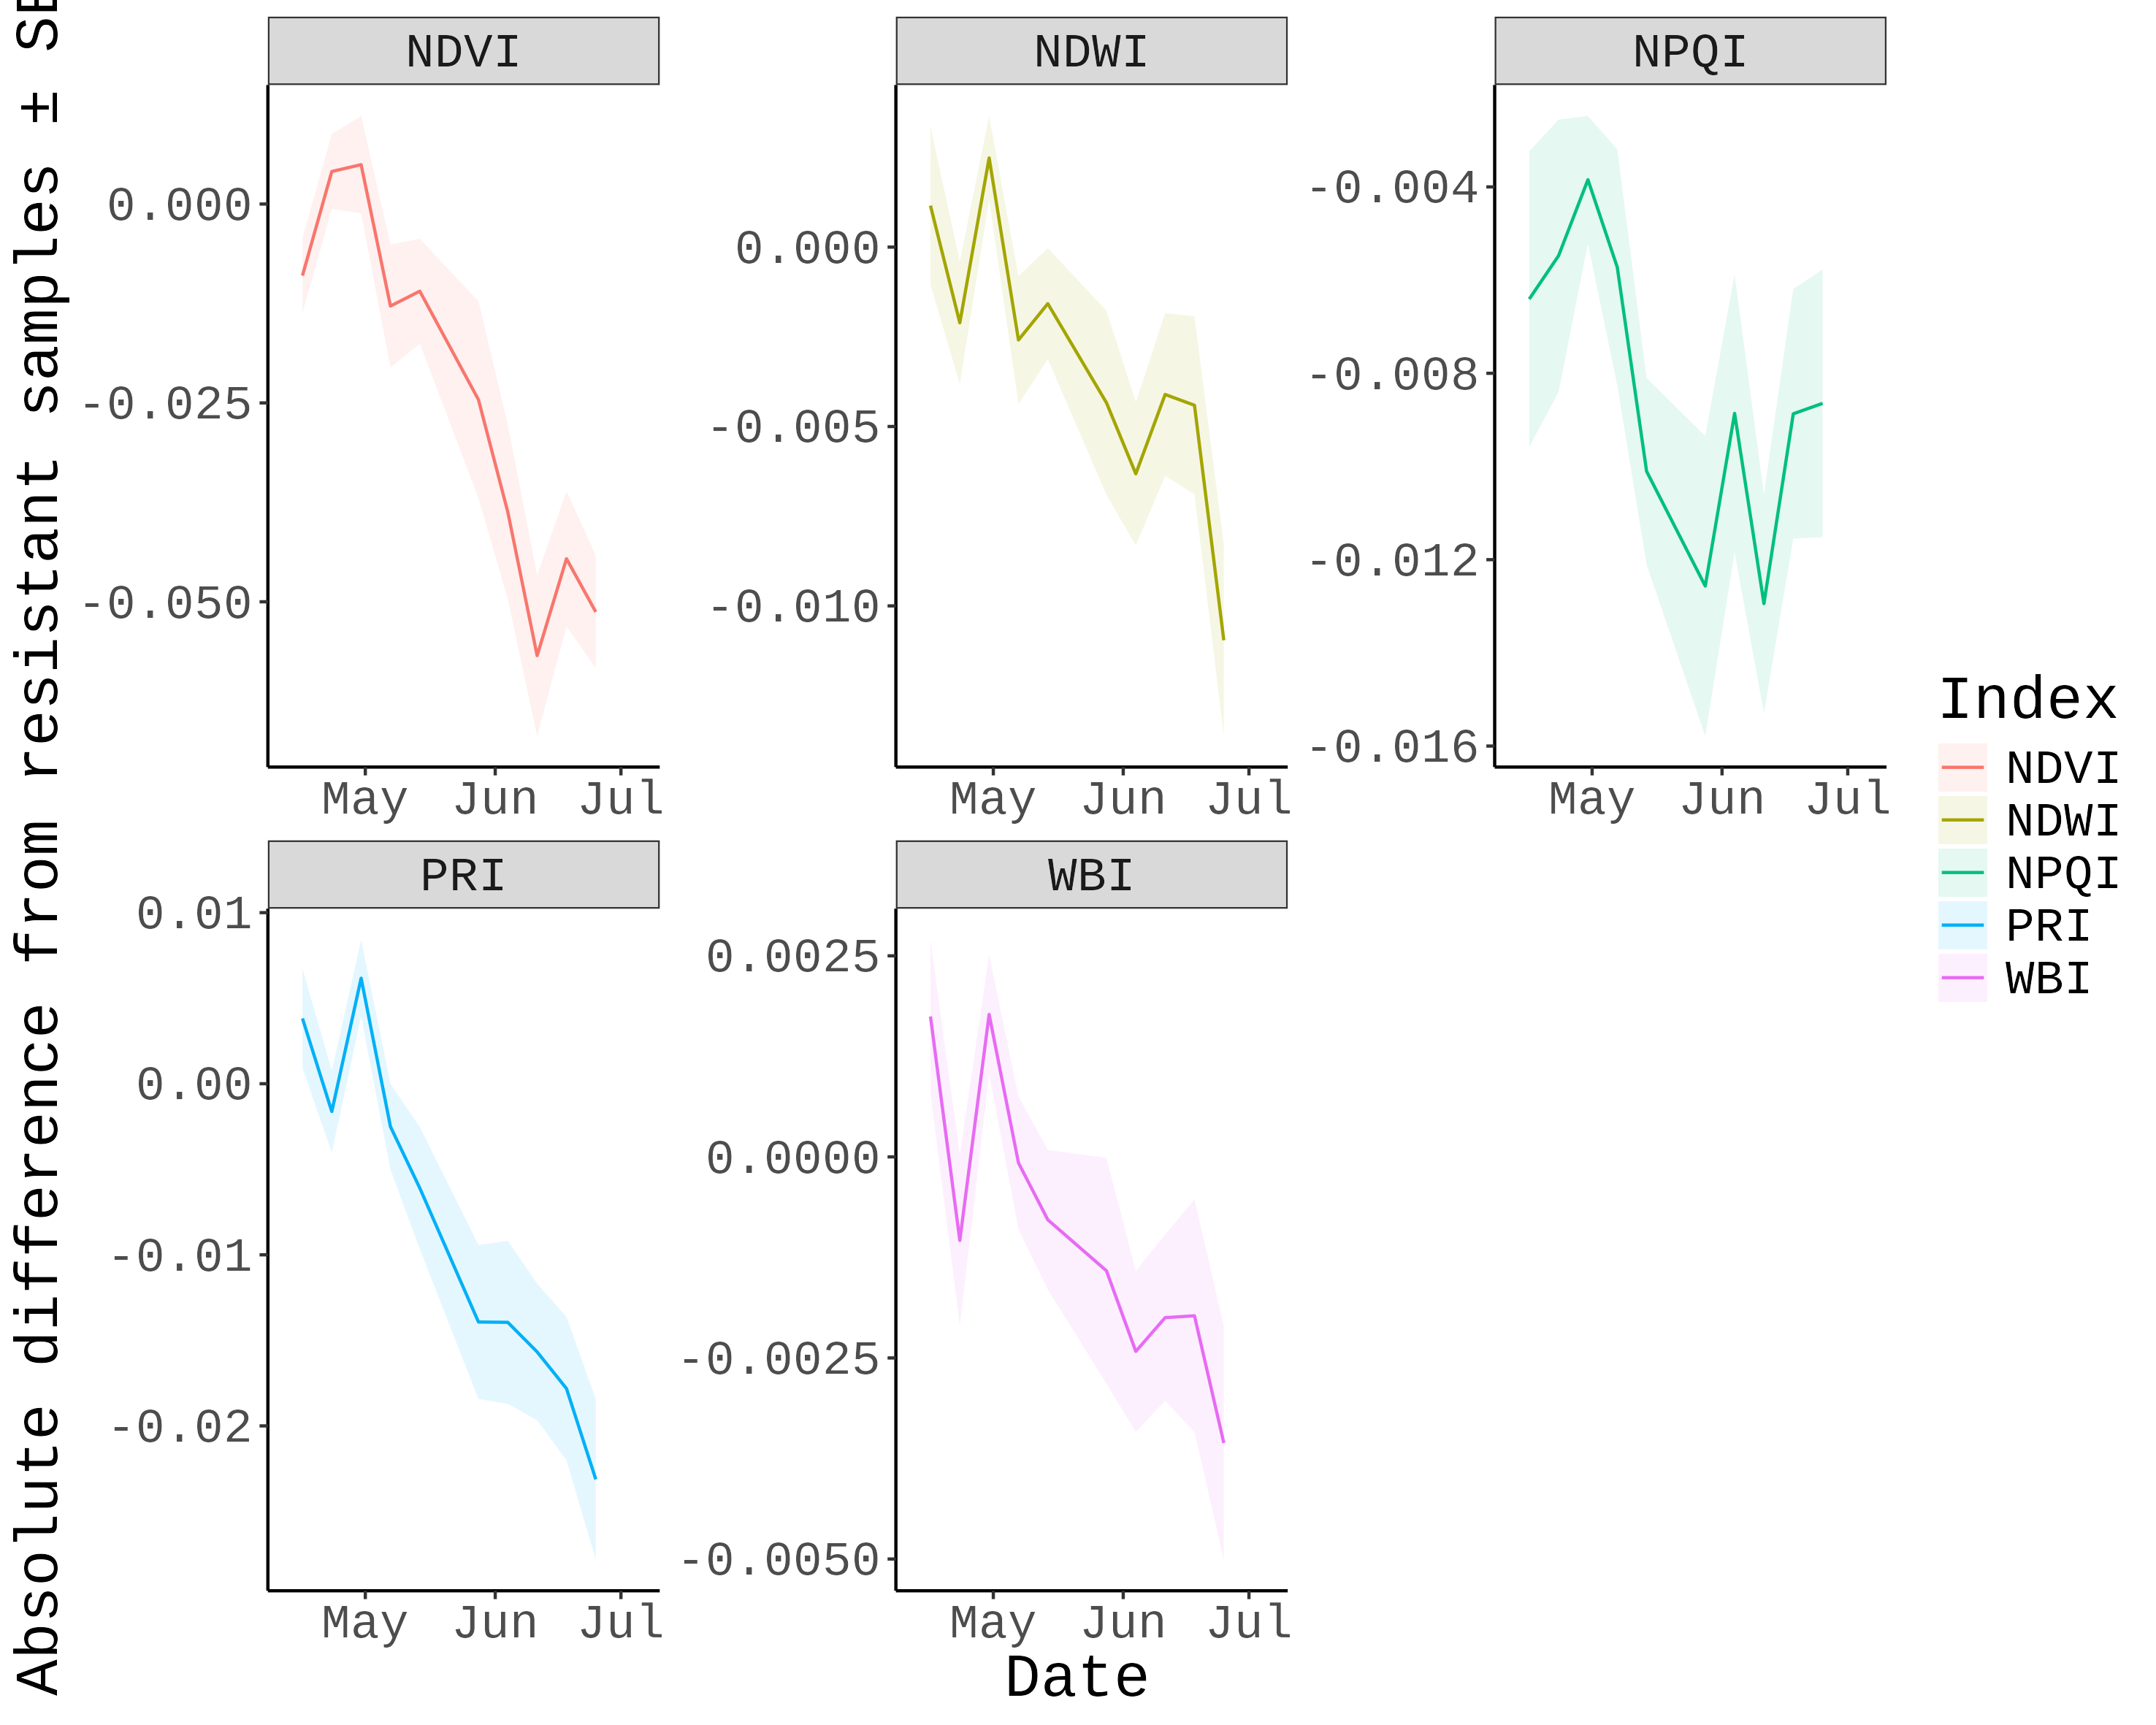

In [ ]:
# Display the authors' saved figure (written by their ggsave calls during the run above).
# 上で著者コードが保存した図を表示します。
from IPython.display import Image, display
display(Image(filename="/content/work/Figure5_IndexDiff.png", width=900))

### Output — Figure6_PhysPlot.png / 出力表示
Authors' Figure 6: LI-600 physiological traits (g_sw, Q_amb, Fv/Fm, VPD, NPQ, T_leaf, PhiPS2, T_ref − T_leaf) for resistant vs susceptible groups, with first spectral/score divergence dates. / 著者の Figure 6: 生理形質の時系列と初回有意日。

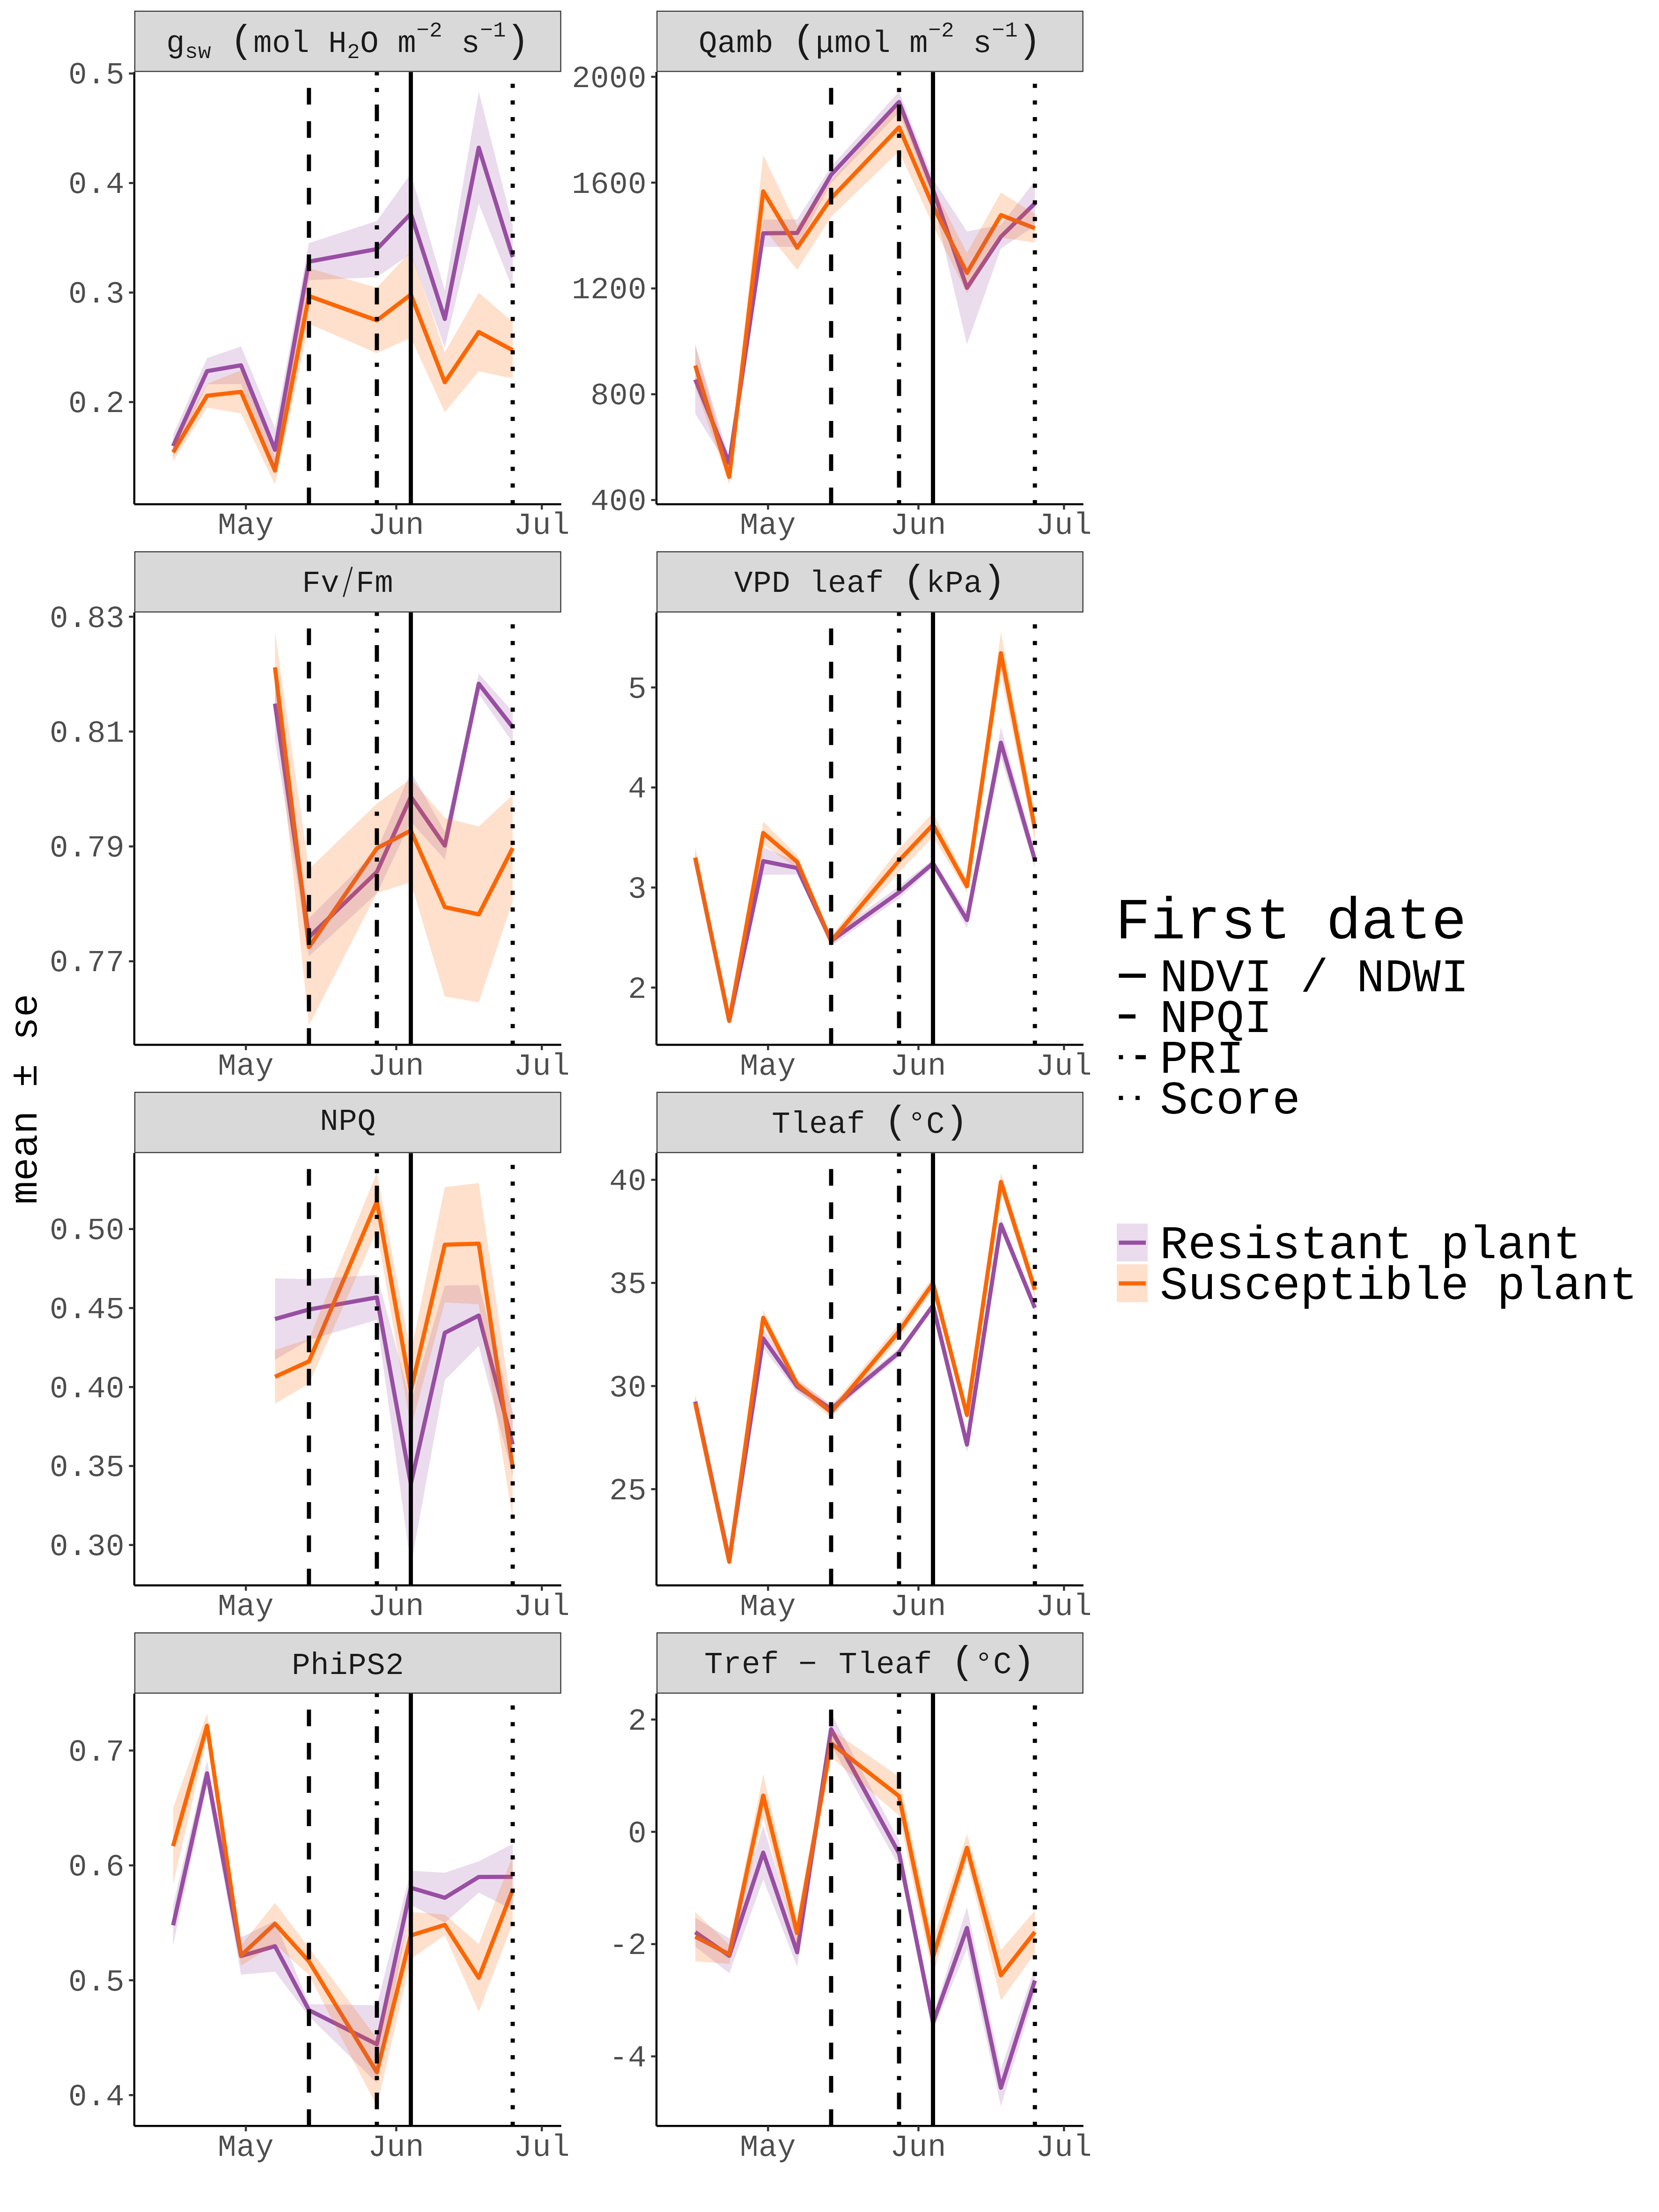

In [ ]:
# Display the authors' saved figure (written by their ggsave calls during the run above).
# 上で著者コードが保存した図を表示します。
from IPython.display import Image, display
display(Image(filename="/content/work/Figure6_PhysPlot.png", width=900))

## Interpretation and validation record / 解釈と検証記録
- The lead-time comparison in the results cell is the key check: the executed authors' code on the authors' dataset is expected to reproduce the paper's Table 1 ordering — NPQI first (2021-05-14), then PRI (2021-05-28), NDVI/NDWI (2021-06-04), and disease score last (2021-06-25) — i.e., a 3–5 week spectral lead before human disease scores.
- Figures 2–6 shown above are produced by the authors' unmodified ggplot code from the pinned Zenodo record (MD5-verified); the input preview is the only AI-created figure.
- Scope is one executed analysis of the deposited code/data; it does not verify claims outside these outputs. Figure 7 full-spectrum analyses (PCoA / CV / Spearman / PERMANOVA) are omitted because they are absent from the deposited script.
- 結果の比較表が主要な検証です。実行した著者コードが論文 Table 1 の順序（NPQI→PRI→NDVI/NDWI→スコア、スペクトル先行 3–5 週間）を再現するかを確認できます。Figure 7 の全スペクトル解析は省略しています。

## References / 参考文献
- Paper: doi:10.1002/ppj2.70046 (Plant Phenome Journal 8(1):e70046, 2025, CC BY 4.0)
- Code & data: Zenodo doi:10.5281/zenodo.16217833 (version record, CC BY 4.0)
- R: executed on the Colab VM with R installed by this notebook; package versions printed above.